In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from pathlib import Path

sns.set_theme(style="whitegrid")
OUT = Path("figures"); OUT.mkdir(exist_ok=True)

COLOURS = {"Developed": "#1f77b4", "Developing": "#d95f02"}
ISO3 = {"Switzerland": "CHE", "United States": "USA", "Germany": "DEU",
        "South Africa": "ZAF", "China": "CHN", "India": "IND"}

pat = pd.read_csv("clean-pt2/patents_summary_6countries.csv")
pat["iso3"] = pat["country"].map(ISO3)
pat["field"] = pat["field"].str.replace(r"_+", " ", regex=True).str.strip()

# Grant rate, left blank where there were no applications
pat["grant_rate"] = (pat["num_patent_granted"] / pat["num_patent_applications"]
                     ).where(pat["num_patent_applications"] > 0)

PARENTS = ["All", "Physical Sciences and Engineering"]
totals = pat[pat["field"] == "All"].copy()
fields = pat[~pat["field"].isin(PARENTS)].copy()

print(totals[["country", "num_patent_applications", "num_patent_granted", "grant_rate"]])
print(fields.groupby("country")["field"].nunique())

           country  num_patent_applications  num_patent_granted  grant_rate
22           China                   866702              377826    0.435935
44         Germany                     8873                3971    0.447537
68           India                      742                 524    0.706199
95    South Africa                      477                 467    0.979036
98     Switzerland                       47                  23    0.489362
102  United States                   107187               83698    0.780860
country
China            31
Germany          31
India            31
South Africa     31
Switzerland      31
United States    31
Name: field, dtype: int64


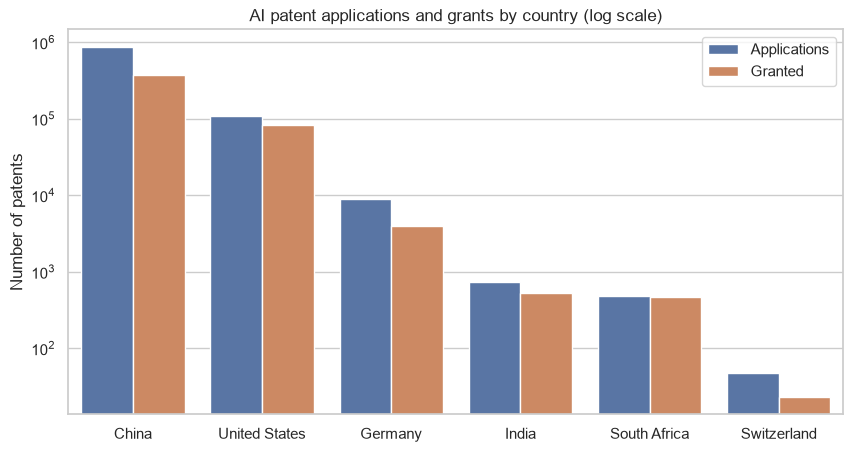

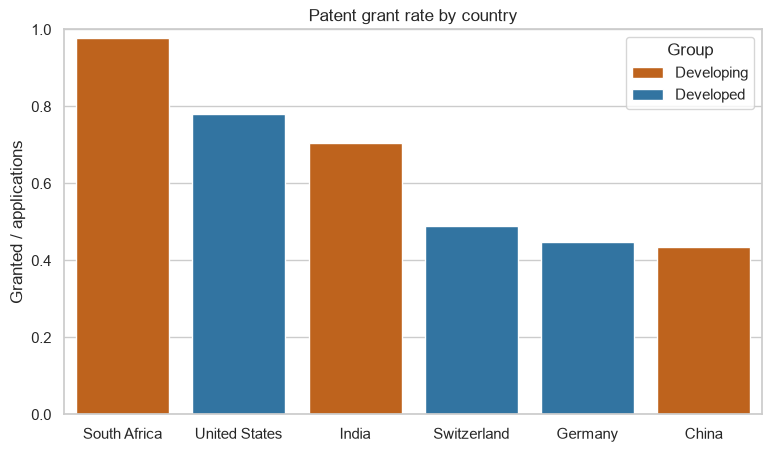

            num_patent_applications  num_patent_granted  grant_rate
group                                                              
Developed                    116107               87692    0.755269
Developing                   867921              378817    0.436465


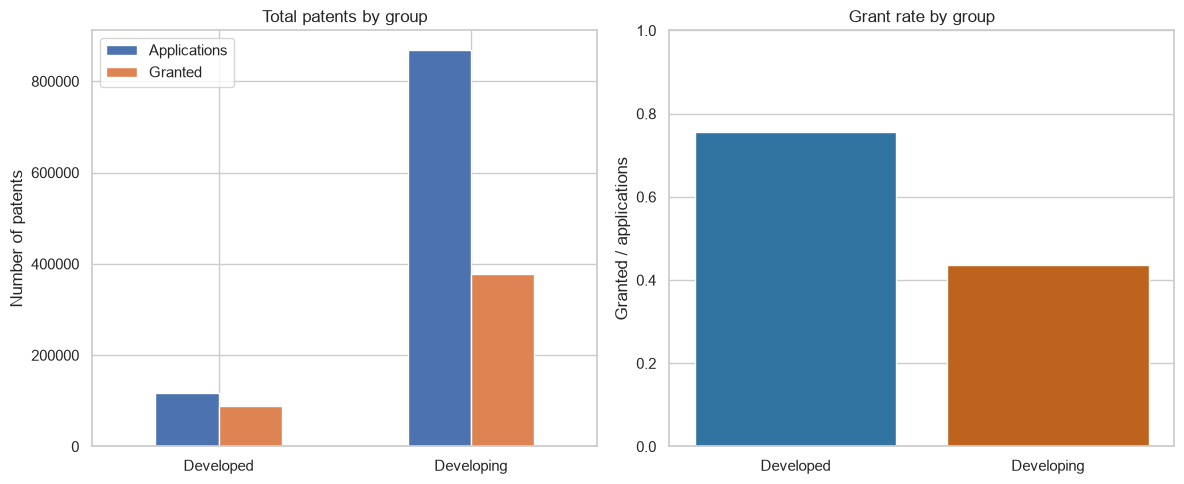

Text(0.5, 1.0, 'Top 10 patent fields by share of group applications')

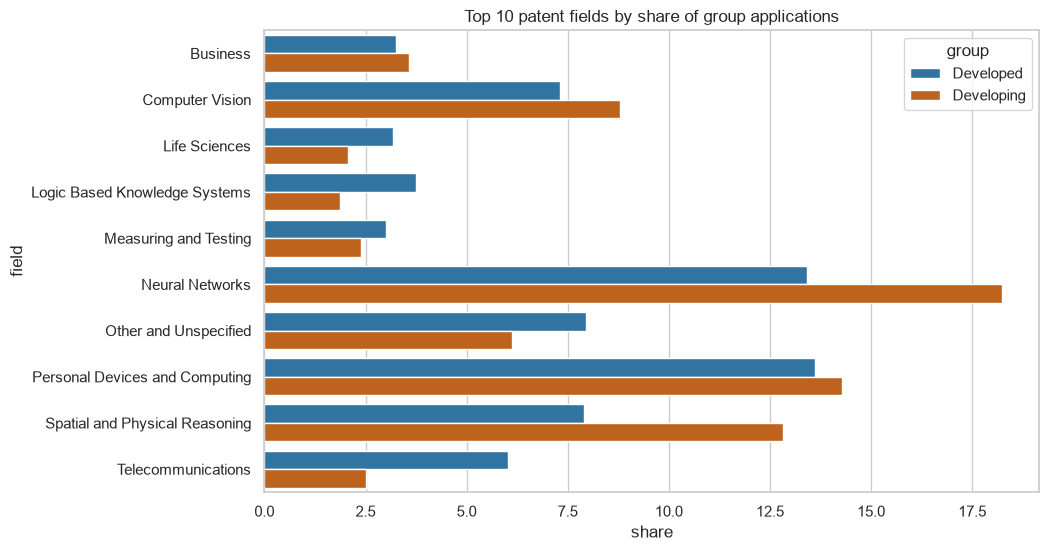

In [3]:
# 1. Applications and grants by country (log scale because China dwarfs the rest)
order = totals.sort_values("num_patent_applications", ascending=False)["country"]
long = totals.melt(id_vars=["country", "group"],
                   value_vars=["num_patent_applications", "num_patent_granted"],
                   var_name="type", value_name="count")
long["type"] = long["type"].map({"num_patent_applications": "Applications",
                                 "num_patent_granted": "Granted"})

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=long, x="country", y="count", hue="type", order=order, ax=ax)
ax.set_yscale("log")
ax.set_title("AI patent applications and grants by country (log scale)")
ax.set_xlabel("")
ax.set_ylabel("Number of patents")
ax.legend(title="")
fig.savefig(OUT / "patents_totals_by_country.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Grant rate by country
order_rate = totals.sort_values("grant_rate", ascending=False)["country"]
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=totals, x="country", y="grant_rate", hue="group",
            palette=COLOURS, order=order_rate, dodge=False, ax=ax)
ax.set_title("Patent grant rate by country")
ax.set_xlabel("")
ax.set_ylabel("Granted / applications")
ax.set_ylim(0, 1)
ax.legend(title="Group")
fig.savefig(OUT / "patents_grant_rate.png", dpi=300, bbox_inches="tight")
plt.show()

# 3. Developed vs developing (group grant rate uses summed counts, not an average of rates)
grp = totals.groupby("group")[["num_patent_applications", "num_patent_granted"]].sum()
grp["grant_rate"] = grp["num_patent_granted"] / grp["num_patent_applications"]
print(grp)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
grp[["num_patent_applications", "num_patent_granted"]].plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Total patents by group")
axes[0].set_xlabel("")
axes[0].set_ylabel("Number of patents")
axes[0].legend(["Applications", "Granted"])

sns.barplot(x=grp.index, y=grp["grant_rate"], hue=grp.index,
            palette=COLOURS, legend=False, ax=axes[1])
axes[1].set_title("Grant rate by group")
axes[1].set_xlabel("")
axes[1].set_ylabel("Granted / applications")
axes[1].set_ylim(0, 1)

fig.tight_layout()
fig.savefig(OUT / "patents_group_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# 4. Top 10 fields by share of each group's field level applications
f = fields.groupby(["group", "field"])["num_patent_applications"].sum().reset_index()
f["share"] = f["num_patent_applications"] / f.groupby("group")["num_patent_applications"].transform("sum") * 100
top10 = f.groupby("field")["share"].sum().nlargest(10).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=f[f["field"].isin(top10)], y="field", x="share",
            hue="group", palette=COLOURS, ax=ax)
ax.set_title("Top 10 patent fields by share of group applications")

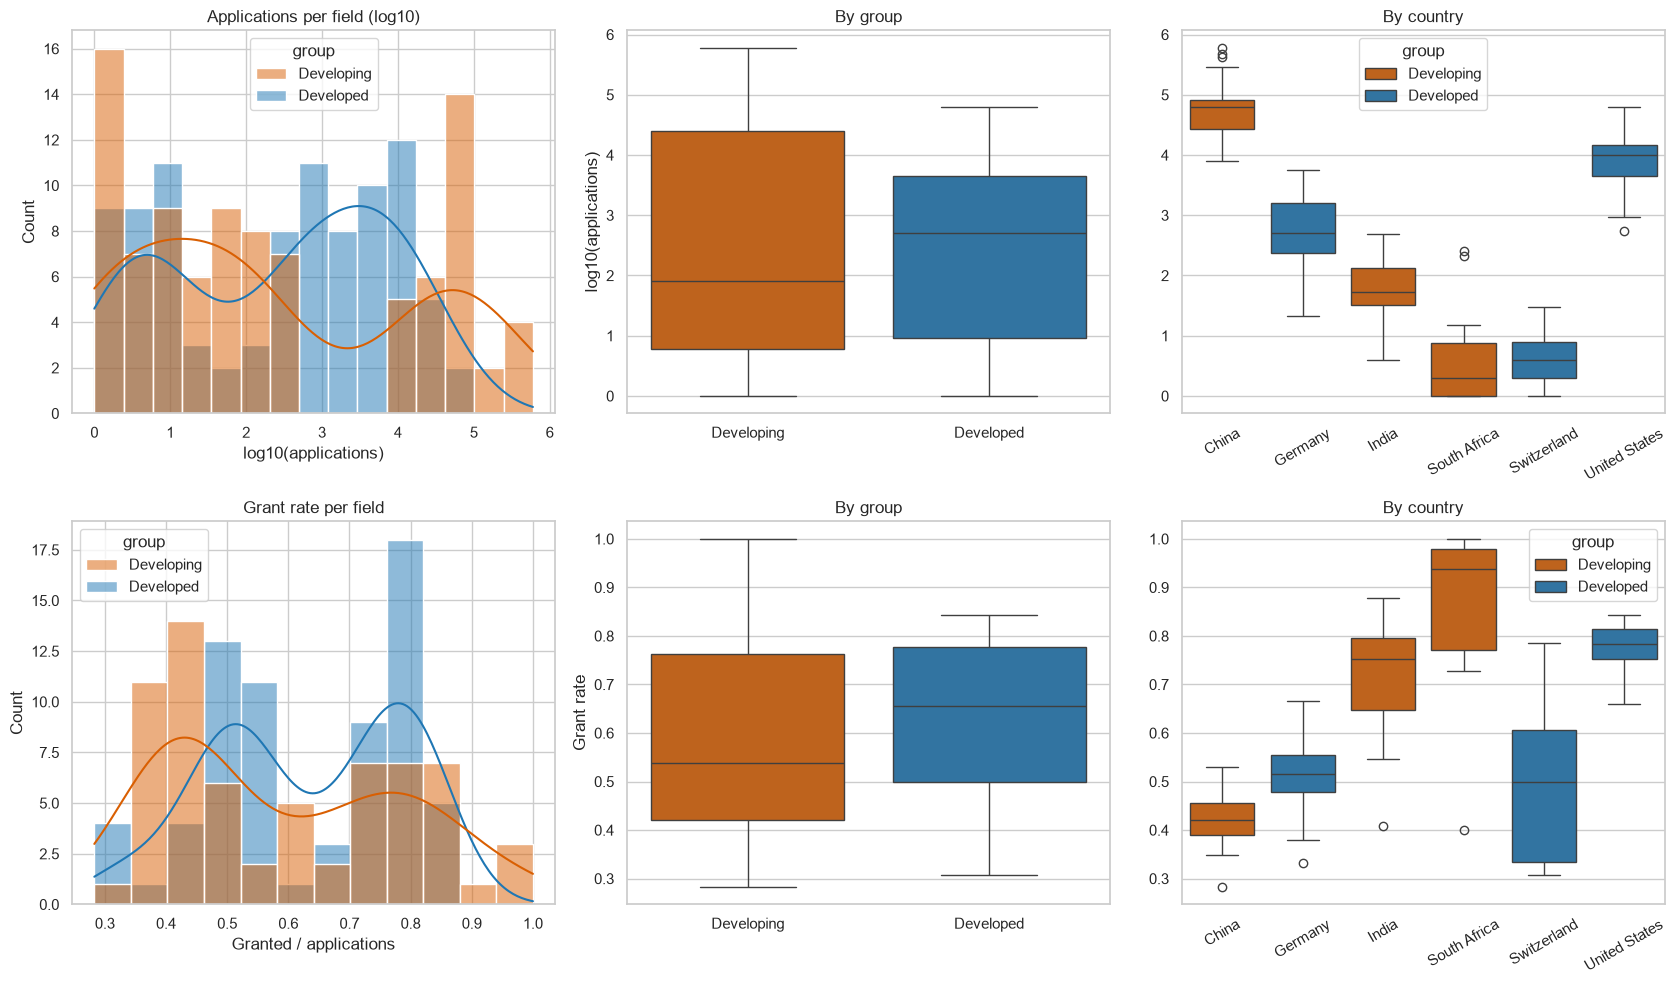

51 field rows excluded from grant rate plots (under 10 applications)


In [4]:
fields["log_apps"] = np.log10(fields["num_patent_applications"].clip(lower=1))
rated = fields[fields["num_patent_applications"] >= 10]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

# Row 1: applications per field (log10)
sns.histplot(data=fields, x="log_apps", hue="group", palette=COLOURS, kde=True, bins=15, alpha=0.5, ax=axes[0, 0])
axes[0, 0].set_title("Applications per field (log10)")
axes[0, 0].set_xlabel("log10(applications)")

sns.boxplot(data=fields, x="group", y="log_apps", hue="group", palette=COLOURS, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("By group")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("log10(applications)")

sns.boxplot(data=fields, x="country", y="log_apps", hue="group", palette=COLOURS, dodge=False, ax=axes[0, 2])
axes[0, 2].set_title("By country")
axes[0, 2].set_xlabel("")
axes[0, 2].set_ylabel("")
axes[0, 2].tick_params(axis="x", rotation=30)

# Row 2: grant rate per field (fields with 10+ applications)
sns.histplot(data=rated, x="grant_rate", hue="group", palette=COLOURS, kde=True, bins=12, alpha=0.5, ax=axes[1, 0])
axes[1, 0].set_title("Grant rate per field")
axes[1, 0].set_xlabel("Granted / applications")

sns.boxplot(data=rated, x="group", y="grant_rate", hue="group", palette=COLOURS, legend=False, ax=axes[1, 1])
axes[1, 1].set_title("By group")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Grant rate")

sns.boxplot(data=rated, x="country", y="grant_rate", hue="group", palette=COLOURS, dodge=False, ax=axes[1, 2])
axes[1, 2].set_title("By country")
axes[1, 2].set_xlabel("")
axes[1, 2].set_ylabel("")
axes[1, 2].tick_params(axis="x", rotation=30)

fig.tight_layout()
fig.savefig(OUT / "patents_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print(len(fields) - len(rated), "field rows excluded from grant rate plots (under 10 applications)")

In [5]:
totals["log_apps"] = np.log10(totals["num_patent_applications"])

# Map 1: applications (log scale colour, real counts in the hover text)
fig = px.choropleth(totals, locations="iso3", color="log_apps",
                    hover_name="country",
                    hover_data={"iso3": False, "log_apps": False,
                                "num_patent_applications": ":,", "num_patent_granted": ":,"},
                    color_continuous_scale="Viridis",
                    labels={"log_apps": "log10(applications)"},
                    title="AI patent applications by country (log10 scale)")
fig.update_geos(showcountries=True, projection_type="natural earth")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(OUT / "patents_applications_map.html")
fig.show()

# Map 2: grant rate
fig = px.choropleth(totals, locations="iso3", color="grant_rate",
                    hover_name="country",
                    hover_data={"iso3": False, "grant_rate": ":.1%"},
                    color_continuous_scale="Viridis", range_color=(0, 1),
                    labels={"grant_rate": "Grant rate"},
                    title="AI patent grant rate by country")
fig.update_geos(showcountries=True, projection_type="natural earth")
fig.update_layout(margin=dict(l=0, r=0, t=50, b=0))
fig.write_html(OUT / "patents_grant_rate_map.html")
fig.show()

In [6]:
for f in sorted(Path("clean-pt2").glob("patents_year*")):
    d = pd.read_csv(f)
    print(f"\n=== {f.name} | {d.shape[0]} rows x {d.shape[1]} cols")
    print(d.head(8).to_string())


=== patents_yearly_applications_6countries.csv | 1947 rows x 6 cols
         country                     field  year  num_patent_applications  complete       group
0          China                       All  2022                   107425     False  Developing
1  United States                       All  2025                      242     False   Developed
2          India                       All  2020                       12      True  Developing
3          India                       All  2021                        6      True  Developing
4  United States  Analytics and Algorithms  2020                     1808      True   Developed
5        Germany  Analytics and Algorithms  2021                      158      True   Developed
6          China  Analytics and Algorithms  2023                    12502     False  Developing
7        Germany       Banking and Finance  2020                       58      True   Developed

=== patents_yearly_granted_6countries.csv | 1815 rows x 6 cols
   

In [7]:
apps = pd.read_csv("clean-pt2/patents_yearly_applications_6countries.csv")
gran = pd.read_csv("clean-pt2/patents_yearly_granted_6countries.csv")

# Keep the EDA window only
apps = apps[apps["year"].between(2018, 2024)].copy()
gran = gran[gran["year"].between(2018, 2024)].copy()

# Country level yearly totals from the "All" rows
apps_all = apps[apps["field"] == "All"]
gran_all = gran[gran["field"] == "All"]

print("Applications, All rows (value, with * where complete is False)")
tbl = apps_all.assign(v=apps_all["num_patent_applications"].astype(str)
                      + np.where(apps_all["complete"], "", "*"))
print(tbl.pivot(index="country", columns="year", values="v").fillna("missing"))

print("\nGranted, All rows")
tbl = gran_all.assign(v=gran_all["num_patent_granted"].astype(str)
                      + np.where(gran_all["complete"], "", "*"))
print(tbl.pivot(index="country", columns="year", values="v").fillna("missing"))

print("\nShare of rows flagged incomplete, by year (applications file)")
print(apps.groupby("year")["complete"].apply(lambda s: (~s).mean()).round(2))

Applications, All rows (value, with * where complete is False)
year            2018   2019   2020   2021     2022     2023     2024
country                                                             
China          30020  48119  71883  92950  107425*  135288*  176802*
Germany          736    987   1186   1174    1379*    1503*     972*
India            270     12     12      6       6*      11*       2*
South Africa       7      5      6     23      71*      99*     134*
Switzerland        4      3      5     11       6*       8*       3*
United States  14638  16515  16913  15629   12135*    8057*    5277*

Granted, All rows
year            2018   2019    2020     2021     2022     2023     2024
country                                                                
China          17896  29712  46843*   57876*   56719*   48826*   57064*
Germany          503    608    647*     497*     457*     303*     220*
India            203      8      4*  missing  missing  missing  missing
South 

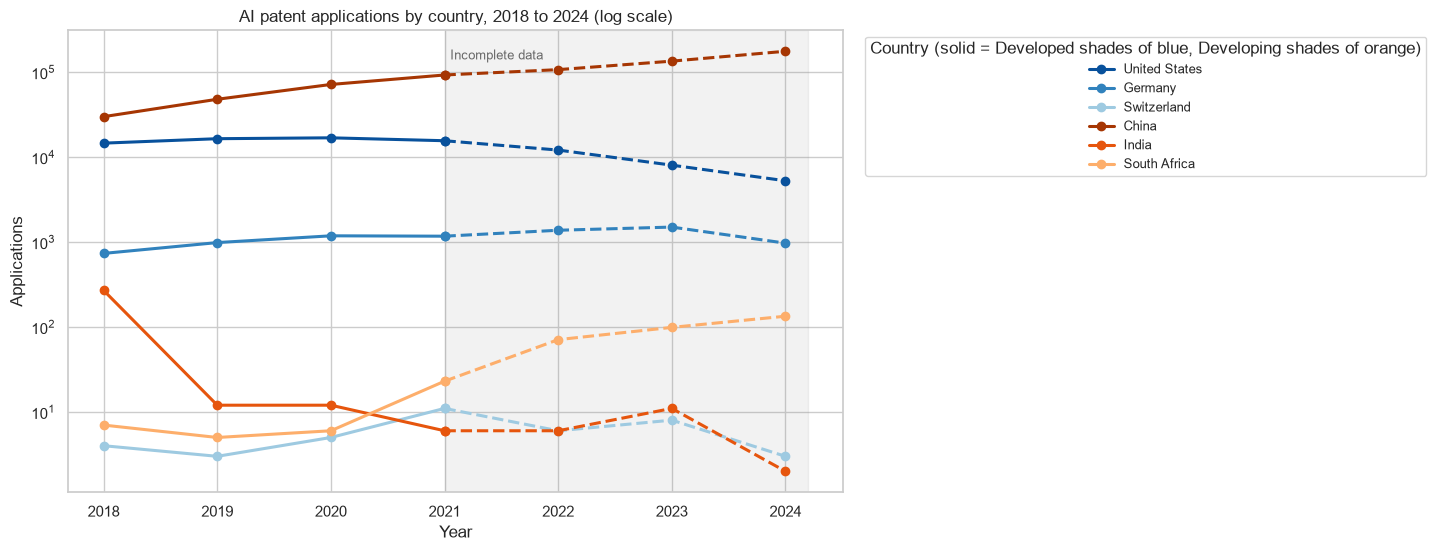

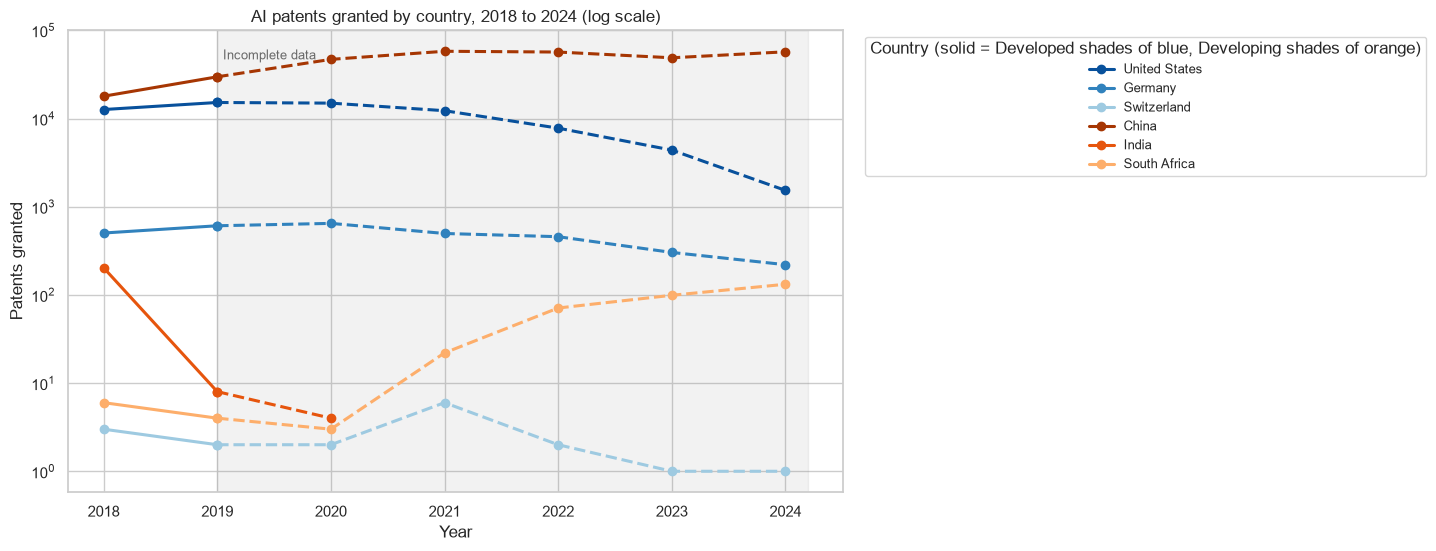

In [8]:
COUNTRY_COLOURS = {
    "United States": "#08519c", "Germany": "#3182bd", "Switzerland": "#9ecae1",
    "China": "#a63603", "India": "#e6550d", "South Africa": "#fdae6b",
}
YEARS = list(range(2018, 2025))


def plot_trend(df, value_col, last_complete, title, ylabel, fname):
    wide = df.pivot(index="year", columns="country", values=value_col).reindex(YEARS)
    fig, ax = plt.subplots(figsize=(10, 6))

    for country in COUNTRY_COLOURS:
        s = wide[country]
        colour = COUNTRY_COLOURS[country]
        ax.plot(s.loc[:last_complete].index, s.loc[:last_complete], color=colour,
                marker="o", linewidth=2.2, label=country)
        ax.plot(s.loc[last_complete:].index, s.loc[last_complete:], color=colour,
                marker="o", linewidth=2.2, linestyle="--")

    ax.axvspan(last_complete, 2024.2, color="grey", alpha=0.10)
    ax.text(last_complete + 0.05, ax.get_ylim()[1], "Incomplete data", va="top", fontsize=9, color="dimgrey")
    ax.set_yscale("log")
    ax.set_xticks(YEARS)
    ax.set_title(title)
    ax.set_xlabel("Year")
    ax.set_ylabel(ylabel)
    ax.legend(title="Country (solid = Developed shades of blue, Developing shades of orange)",
              bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
    fig.savefig(OUT / fname, dpi=300, bbox_inches="tight")
    plt.show()


plot_trend(apps_all, "num_patent_applications", 2021,
           "AI patent applications by country, 2018 to 2024 (log scale)",
           "Applications", "patents_trend_applications.png")

plot_trend(gran_all, "num_patent_granted", 2019,
           "AI patents granted by country, 2018 to 2024 (log scale)",
           "Patents granted", "patents_trend_granted.png")

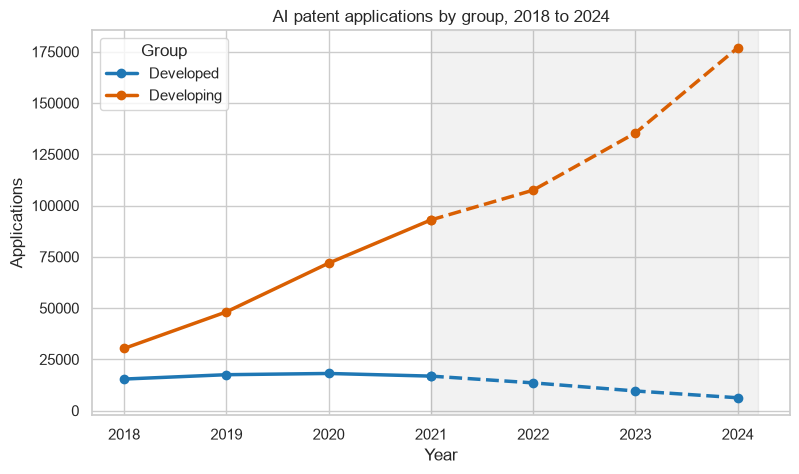

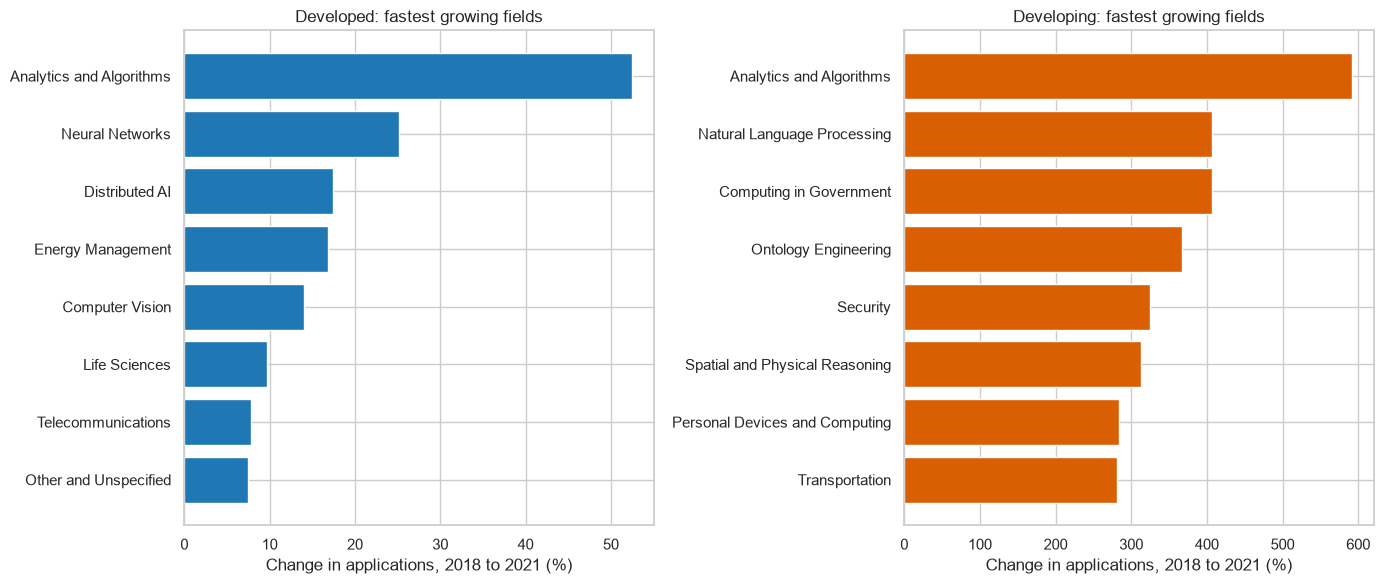

group
Developed     30
Developing    30
Name: field, dtype: int64 fields met the 100 application threshold


In [9]:
# Part 1: group level trend
grp_yr = apps_all.groupby(["year", "group"])["num_patent_applications"].sum().unstack().reindex(YEARS)

fig, ax = plt.subplots(figsize=(9, 5))
for g in ["Developed", "Developing"]:
    ax.plot(grp_yr.index[:4], grp_yr[g].iloc[:4], color=COLOURS[g], marker="o", linewidth=2.5, label=g)
    ax.plot(grp_yr.index[3:], grp_yr[g].iloc[3:], color=COLOURS[g], marker="o", linewidth=2.5, linestyle="--")
ax.axvspan(2021, 2024.2, color="grey", alpha=0.10)
ax.set_xticks(YEARS)
ax.set_title("AI patent applications by group, 2018 to 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Applications")
ax.legend(title="Group")
fig.savefig(OUT / "patents_trend_group.png", dpi=300, bbox_inches="tight")
plt.show()

# Part 2: fastest growing fields, 2018 to 2021 (complete years only)
skip = ["All", "Physical Sciences and Engineering"]
fy = apps[(~apps["field"].isin(skip)) & (apps["year"].isin([2018, 2021]))]
fy = fy.groupby(["group", "field", "year"])["num_patent_applications"].sum().unstack(fill_value=0)
fy = fy[fy[2018] >= 100].copy()
fy["growth_pct"] = (fy[2021] / fy[2018] - 1) * 100
fy = fy.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=False)
for ax, g in zip(axes, ["Developed", "Developing"]):
    d = fy[fy["group"] == g].nlargest(8, "growth_pct").sort_values("growth_pct")
    ax.barh(d["field"], d["growth_pct"], color=COLOURS[g])
    ax.set_title(f"{g}: fastest growing fields")
    ax.set_xlabel("Change in applications, 2018 to 2021 (%)")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(OUT / "patents_field_growth.png", dpi=300, bbox_inches="tight")
plt.show()

print(fy.groupby("group")["field"].count(), "fields met the 100 application threshold")

In [10]:
for f in sorted(Path("clean-pt2").glob("publication*")):
    d = pd.read_csv(f)
    print(f"\n=== {f.name} | {d.shape[0]} rows x {d.shape[1]} cols")
    print(d.head(8).to_string())
    print("years:", sorted(d["year"].unique()) if "year" in d.columns else "no year column")
    print("fields with All row:", (d["field"] == "All").any() if "field" in d.columns else "no field column")


=== publications_summary_6countries.csv | 36 rows x 5 cols
         country      field  num_articles  num_citations       group
0    Switzerland  AI Safety           719          34445   Developed
1  United States  AI Safety         16201        1053019   Developed
2        Germany  AI Safety          3524         118568   Developed
3          China  AI Safety          9885         340999  Developing
4   South Africa  AI Safety           116           2455  Developing
5          India  AI Safety          3120          38121  Developing
6   South Africa        All          6681         147419  Developing
7  United States        All        376956       15302556   Developed
years: no year column
fields with All row: True

=== publications_yearly_articles_6countries.csv | 388 rows x 6 cols
         country                  field  year  num_articles  complete       group
0    Switzerland              AI Safety  2017            23      True   Developed
1   South Africa              AI Safet